# Penguin Species Classification

**Research question:** Can penguin species be predicted from four physical measurements alone, without using island or sex as model inputs? What additional structure is revealed when the same measurements are clustered without species labels?

The supervised task is a three-class classification problem. The unsupervised section is descriptive and does not influence model selection. The aim is to demonstrate a complete and reproducible machine-learning investigation rather than maximize a leaderboard score.

## 1. Data source and roles

The data are the Palmer Penguins dataset distributed with Seaborn. The observations were originally collected at Palmer Station in Antarctica by Dr. Kristen Gorman and the Palmer Station Long Term Ecological Research program.

- Source package: [Seaborn `penguins` dataset](https://github.com/mwaskom/seaborn-data/blob/master/penguins.csv)
- Original project: [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/)
- Features: bill length, bill depth, flipper length, and body mass
- Target: species
- Metadata used only for error analysis: island and sex

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    adjusted_rand_score,
    classification_report,
    f1_score,
    normalized_mutual_info_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from penguins_project.data import validate_penguins
from penguins_project.train import (
    ASSIGNMENTS_PATH,
    DF_PARQUET_PATH,
    ID_COLUMN,
    METADATA,
    MODEL_DATA_PATH,
    MODEL_FEATURES,
    SEED,
    SPLIT_COLUMN,
    TARGET_COLUMN,
)

sns.set_theme(style="whitegrid", context="notebook")

SPECIES_ORDER = ["Adelie", "Chinstrap", "Gentoo"]
SPECIES_PALETTE = {
    "Adelie": "#4C78A8",
    "Chinstrap": "#F58518",
    "Gentoo": "#54A24B",
}

## 2. Load and validate the data

In [2]:
raw_data = pd.read_parquet(DF_PARQUET_PATH)
validate_penguins(raw_data)

model_data = pd.read_parquet(MODEL_DATA_PATH)
assignments = pd.read_parquet(ASSIGNMENTS_PATH)

data_with_split = model_data.merge(
    assignments,
    on=ID_COLUMN,
    validate="one_to_one",
)

assert len(data_with_split) == 342
assert data_with_split[ID_COLUMN].is_unique
assert data_with_split[SPLIT_COLUMN].notna().all()
assert data_with_split[list(MODEL_FEATURES)].notna().all().all()

pd.crosstab(
    data_with_split[SPLIT_COLUMN],
    data_with_split[TARGET_COLUMN],
    margins=True,
)

species,Adelie,Chinstrap,Gentoo,All
split,,,,
test,23,10,19,52
train,106,47,86,239
validate,22,11,18,51
All,151,68,123,342


In [3]:
train_df = data_with_split.loc[
    data_with_split[SPLIT_COLUMN] == "train"
].copy()
validate_df = data_with_split.loc[
    data_with_split[SPLIT_COLUMN] == "validate"
].copy()
test_df = data_with_split.loc[
    data_with_split[SPLIT_COLUMN] == "test"
].copy()

print("Train:", train_df.shape)
print("Validation:", validate_df.shape)
print("Test:", test_df.shape)

Train: (239, 9)
Validation: (51, 9)
Test: (52, 9)


Two observations with all four physical measurements missing were excluded before splitting. The remaining 342 observations were assigned to deterministic, stratified train/validation/test partitions (70/15/15). The test set remains untouched until the final model has been selected.

## 3. Exploratory analysis of the training split

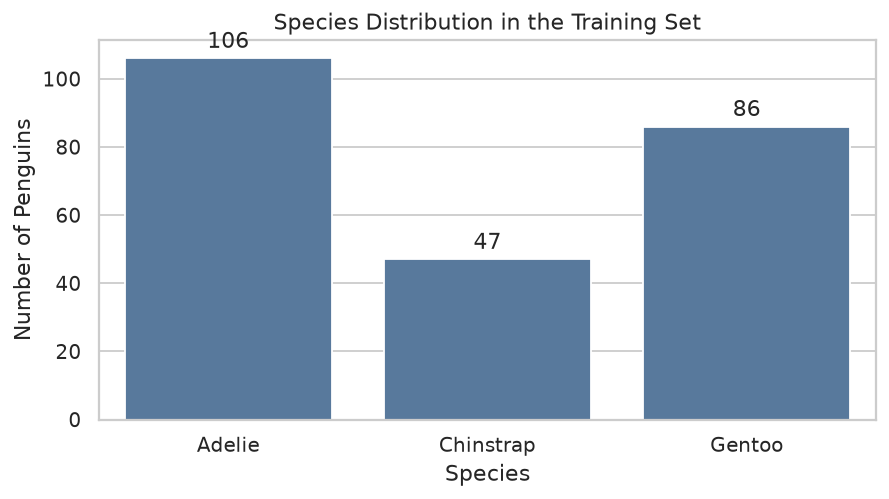

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(
    data=train_df,
    x=TARGET_COLUMN,
    order=SPECIES_ORDER,
    color="#4C78A8",
    ax=ax,
)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Species Distribution in the Training Set")
ax.set_xlabel("Species")
ax.set_ylabel("Number of Penguins")
plt.tight_layout()
plt.show()

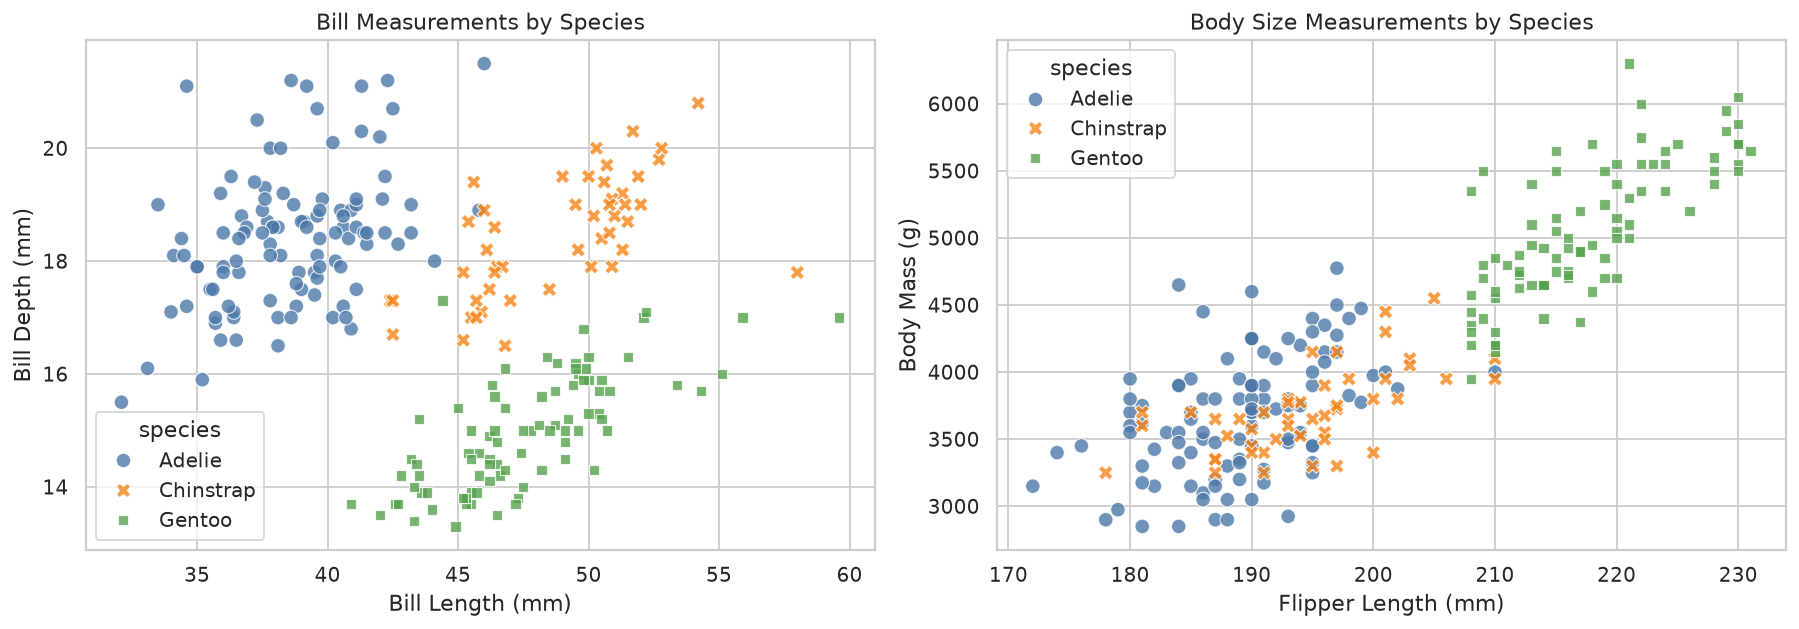

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=train_df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue=TARGET_COLUMN,
    style=TARGET_COLUMN,
    hue_order=SPECIES_ORDER,
    style_order=SPECIES_ORDER,
    palette=SPECIES_PALETTE,
    s=65,
    alpha=0.8,
    ax=axes[0],
)
axes[0].set_title("Bill Measurements by Species")
axes[0].set_xlabel("Bill Length (mm)")
axes[0].set_ylabel("Bill Depth (mm)")

sns.scatterplot(
    data=train_df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue=TARGET_COLUMN,
    style=TARGET_COLUMN,
    hue_order=SPECIES_ORDER,
    style_order=SPECIES_ORDER,
    palette=SPECIES_PALETTE,
    s=65,
    alpha=0.8,
    ax=axes[1],
)
axes[1].set_title("Body Size Measurements by Species")
axes[1].set_xlabel("Flipper Length (mm)")
axes[1].set_ylabel("Body Mass (g)")

plt.tight_layout()
plt.show()

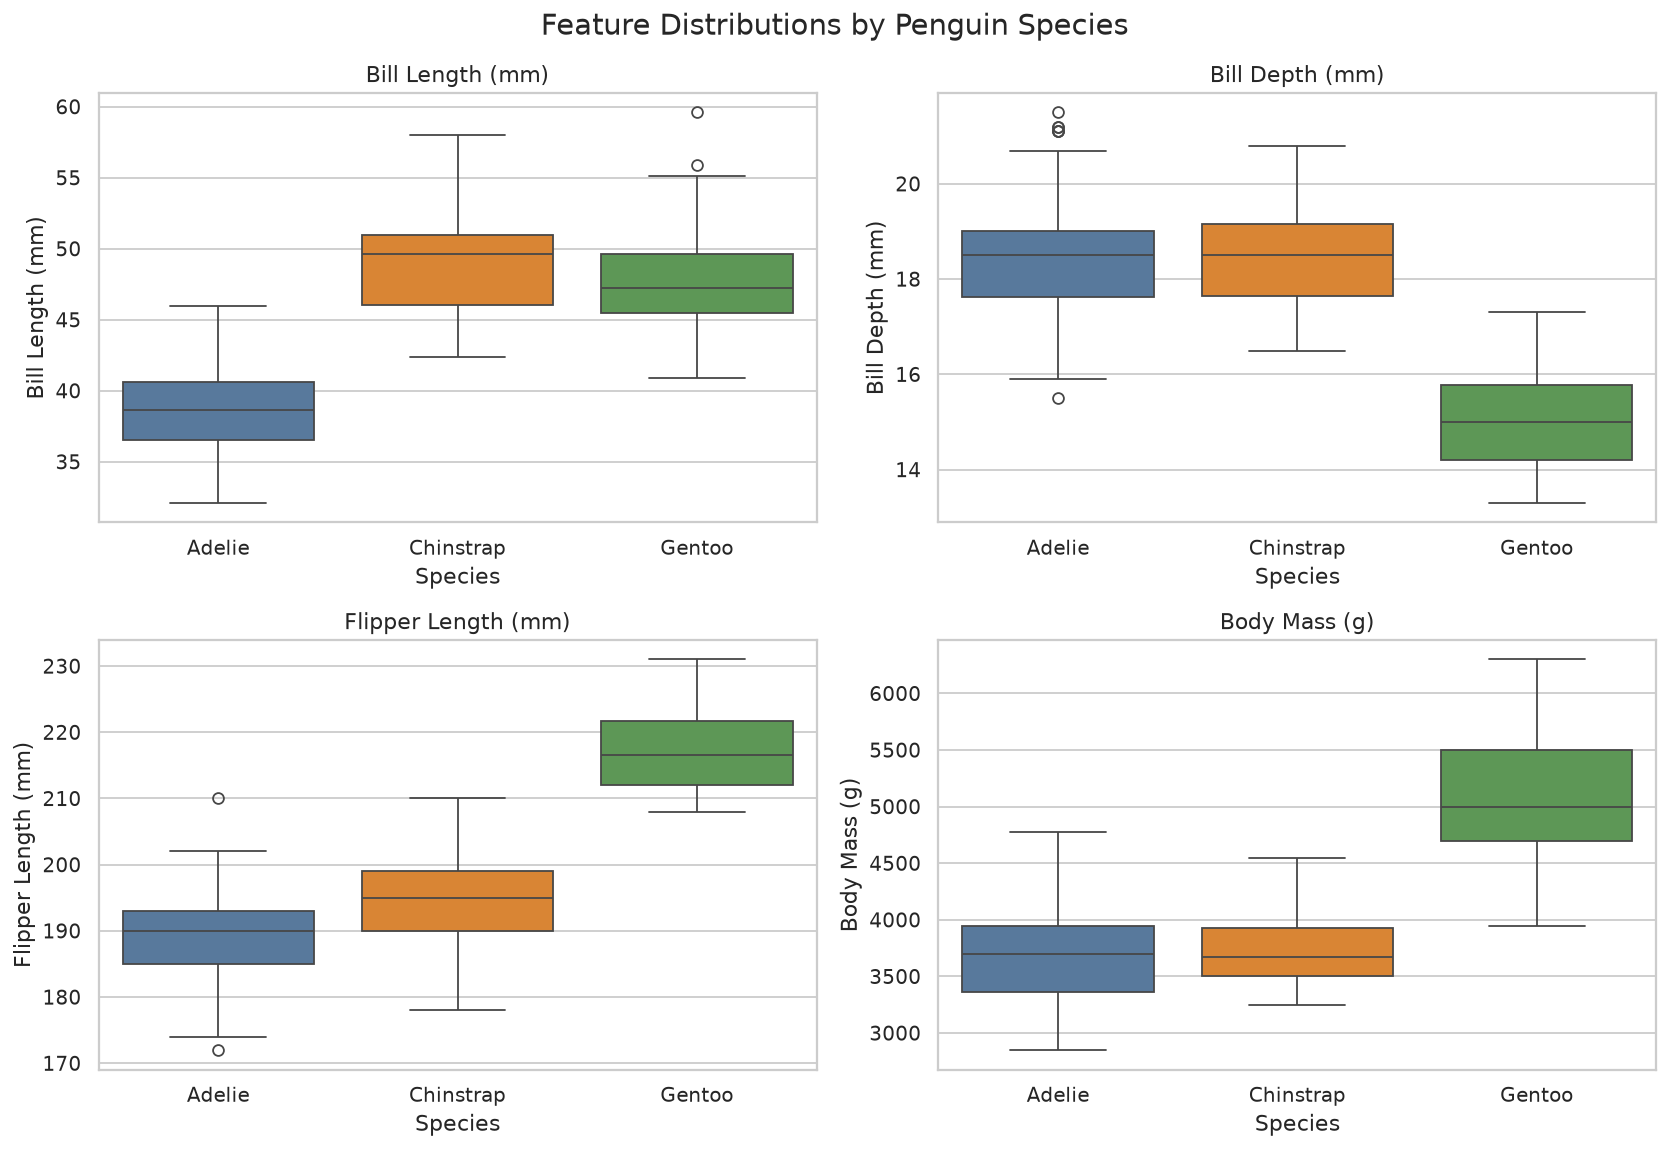

In [6]:
FEATURE_LABELS = {
    "bill_length_mm": "Bill Length (mm)",
    "bill_depth_mm": "Bill Depth (mm)",
    "flipper_length_mm": "Flipper Length (mm)",
    "body_mass_g": "Body Mass (g)",
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, feature in zip(axes.flat, MODEL_FEATURES):
    sns.boxplot(
        data=train_df,
        x=TARGET_COLUMN,
        y=feature,
        order=SPECIES_ORDER,
        hue=TARGET_COLUMN,
        hue_order=SPECIES_ORDER,
        palette=SPECIES_PALETTE,
        dodge=False,
        legend=False,
        ax=ax,
    )
    ax.set_title(FEATURE_LABELS[feature])
    ax.set_xlabel("Species")
    ax.set_ylabel(FEATURE_LABELS[feature])

fig.suptitle("Feature Distributions by Penguin Species", fontsize=16)
plt.tight_layout()
plt.show()

Adelie is the largest class and Chinstrap the smallest, so accuracy is reported together with macro F1. The plots show substantial morphological separation, especially for Gentoo, while Adelie and Chinstrap overlap more in some measurements. This makes a linear classifier plausible, while a tree ensemble provides a nonlinear comparison.

## 4. Model inputs and leakage-safe evaluation

In [7]:
def split_xy(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    X = frame[list(MODEL_FEATURES)].copy()
    y = frame[TARGET_COLUMN].copy()
    return X, y


X_train, y_train = split_xy(train_df)
X_validate, y_validate = split_xy(validate_df)
X_test, y_test = split_xy(test_df)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_validate.shape, y_validate.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (239, 4) (239,)
Validation: (51, 4) (51,)
Test: (52, 4) (52,)


The most-frequent classifier is the baseline. Logistic Regression is a simple interpretable linear candidate and requires scaling. Random Forest provides a nonlinear comparison and does not require scaling. All preprocessing is inside a scikit-learn `Pipeline`, so the scaler is fitted separately within each cross-validation fold and cannot use validation-fold information.

Candidate models are compared with five-fold stratified cross-validation on the training partition. Macro F1 is the primary selection metric because it gives equal importance to all three species. The fixed validation partition provides a secondary confirmation before the chosen model is refitted on train plus validation data. The test set is evaluated once.

In [8]:
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            (
                "classifier",
                LogisticRegression(max_iter=1_000, random_state=SEED),
            ),
        ]
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=1,
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)
scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
}

cv_rows = []
for model_name, model in models.items():
    scores = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
    )
    cv_rows.append(
        {
            "model": model_name,
            "accuracy_mean": scores["test_accuracy"].mean(),
            "accuracy_std": scores["test_accuracy"].std(),
            "macro_f1_mean": scores["test_macro_f1"].mean(),
            "macro_f1_std": scores["test_macro_f1"].std(),
        }
    )

cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values("macro_f1_mean", ascending=False)
    .reset_index(drop=True)
)

cv_results.style.format(
    {
        "accuracy_mean": "{:.3f}",
        "accuracy_std": "{:.3f}",
        "macro_f1_mean": "{:.3f}",
        "macro_f1_std": "{:.3f}",
    }
)

,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
0,Logistic Regression,0.988,0.010,0.985,0.012
1,Random Forest,0.975,0.024,0.971,0.027
2,Dummy baseline,0.444,0.008,0.205,0.003


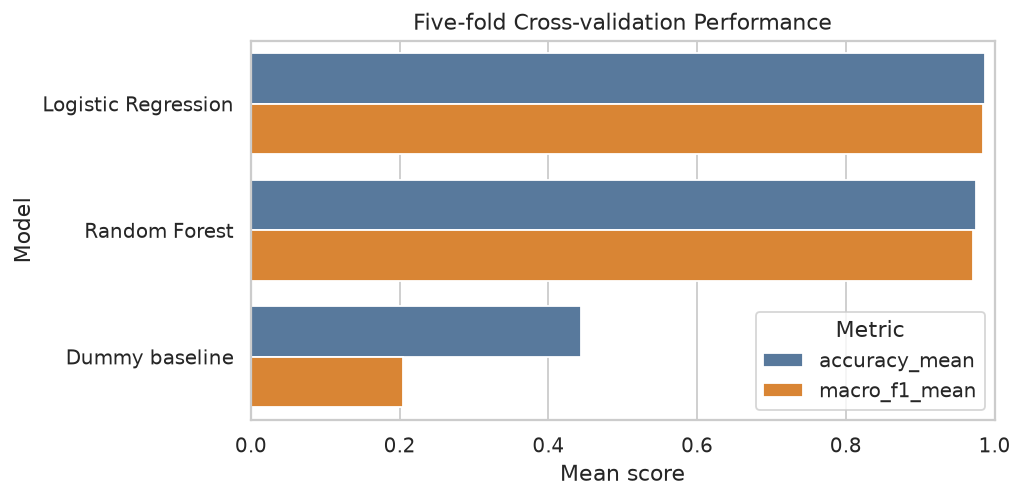

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_results = cv_results.melt(
    id_vars="model",
    value_vars=["accuracy_mean", "macro_f1_mean"],
    var_name="metric",
    value_name="score",
)
sns.barplot(
    data=plot_results,
    x="score",
    y="model",
    hue="metric",
    palette={"accuracy_mean": "#4C78A8", "macro_f1_mean": "#F58518"},
    ax=ax,
)
ax.set_xlim(0, 1)
ax.set_title("Five-fold Cross-validation Performance")
ax.set_xlabel("Mean score")
ax.set_ylabel("Model")
ax.legend(title="Metric")
plt.tight_layout()
plt.show()

## 5. Select the model and evaluate the untouched test set

In [10]:
candidate_results = cv_results.loc[
    cv_results["model"] != "Dummy baseline"
]
best_model_name = candidate_results.iloc[0]["model"]
best_cv_macro_f1 = candidate_results.iloc[0]["macro_f1_mean"]
best_cv_macro_f1_std = candidate_results.iloc[0]["macro_f1_std"]

selected_on_train = clone(models[best_model_name])
selected_on_train.fit(X_train, y_train)
validation_predictions = selected_on_train.predict(X_validate)
validation_accuracy = accuracy_score(y_validate, validation_predictions)
validation_macro_f1 = f1_score(
    y_validate,
    validation_predictions,
    average="macro",
)

development_df = pd.concat([train_df, validate_df], ignore_index=True)
X_development, y_development = split_xy(development_df)

final_model = clone(models[best_model_name])
final_model.fit(X_development, y_development)
test_predictions = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(y_test, test_predictions, average="macro")

print("Selected model:", best_model_name)
print(f"CV macro F1: {best_cv_macro_f1:.3f} ± {best_cv_macro_f1_std:.3f}")
print(f"Validation accuracy: {validation_accuracy:.3f}")
print(f"Validation macro F1: {validation_macro_f1:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test macro F1: {test_macro_f1:.3f}")

Selected model: Logistic Regression
CV macro F1: 0.985 ± 0.012
Validation accuracy: 0.980
Validation macro F1: 0.977
Test accuracy: 0.981
Test macro F1: 0.975


In [11]:
classification_report_df = pd.DataFrame(
    classification_report(
        y_test,
        test_predictions,
        labels=SPECIES_ORDER,
        output_dict=True,
        zero_division=0,
    )
).T
classification_report_df.round(3)

,precision,recall,f1-score,support
Adelie,0.958,1.000,0.979,23.000
Chinstrap,1.000,0.900,0.947,10.000
Gentoo,1.000,1.000,1.000,19.000
accuracy,0.981,0.981,0.981,0.981
macro avg,0.986,0.967,0.975,52.000
weighted avg,0.982,0.981,0.980,52.000


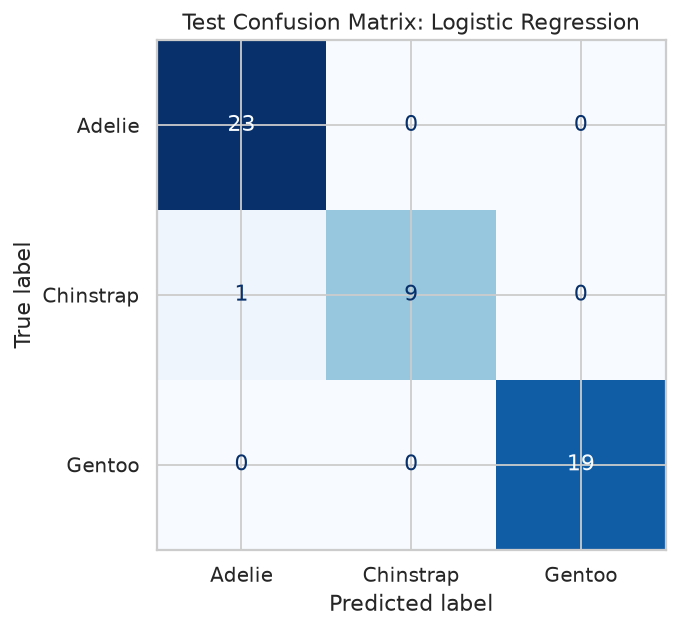

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=SPECIES_ORDER,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"Test Confusion Matrix: {best_model_name}")
plt.tight_layout()
plt.show()

## 6. Error analysis

In [13]:
error_columns = [ID_COLUMN, TARGET_COLUMN, *MODEL_FEATURES, *METADATA]
test_results = test_df[error_columns].copy()
test_results["predicted_species"] = test_predictions
test_results["correct"] = (
    test_results[TARGET_COLUMN] == test_results["predicted_species"]
)
errors = test_results.loc[~test_results["correct"]].copy()

print(f"Test errors: {len(errors)} of {len(test_results)}")
errors

Test errors: 1 of 52


,id,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island,sex,predicted_species,correct
215,216,Chinstrap,43.5,18.1,202.0,3400.0,Dream,Female,Adelie,False


In [14]:
def subgroup_summary(frame: pd.DataFrame, group_column: str) -> pd.DataFrame:
    summary = (
        frame.groupby(group_column, dropna=False)
        .agg(
            observations=("correct", "size"),
            correct_predictions=("correct", "sum"),
            accuracy=("correct", "mean"),
        )
        .reset_index()
    )
    summary["errors"] = (
        summary["observations"] - summary["correct_predictions"]
    )
    return summary


print("Accuracy by island")
display(subgroup_summary(test_results, "island"))
print("Accuracy by sex (metadata only)")
display(subgroup_summary(test_results, "sex"))

Accuracy by island
Accuracy by sex (metadata only)


,island,observations,correct_predictions,accuracy,errors
0,Biscoe,28,28,1.000000,0
1,Dream,18,17,0.944444,1
2,Torgersen,6,6,1.000000,0


,sex,observations,correct_predictions,accuracy,errors
0,Female,26,25,0.961538,1
1,Male,24,24,1.000000,0
2,NaN,2,2,1.000000,0


Subgroup results are descriptive only because the test set and several subgroups are small. Island and sex were not used as predictors. They are inspected only to see whether the few remaining mistakes are concentrated in a particular subgroup.

## 7. Model-agnostic feature importance

In [15]:
permutation_result = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=30,
    random_state=SEED,
    n_jobs=1,
)

importance_df = (
    pd.DataFrame(
        {
            "feature": MODEL_FEATURES,
            "importance_mean": permutation_result.importances_mean,
            "importance_std": permutation_result.importances_std,
        }
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
importance_df

,feature,importance_mean,importance_std
0,bill_length_mm,0.359542,0.070634
1,bill_depth_mm,0.139458,0.045745
2,body_mass_g,0.071176,0.026539
3,flipper_length_mm,0.014000,0.019704


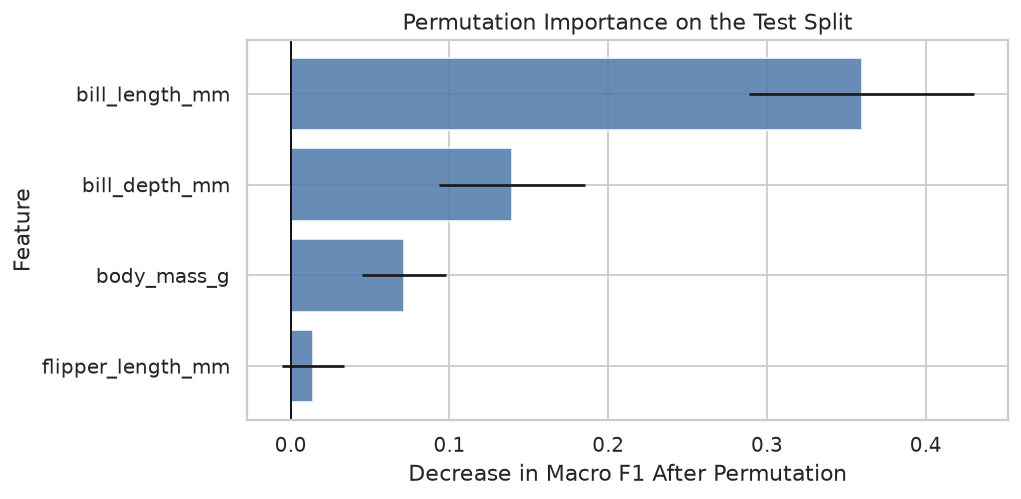

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ordered_importance = importance_df.sort_values("importance_mean")
ax.barh(
    ordered_importance["feature"],
    ordered_importance["importance_mean"],
    xerr=ordered_importance["importance_std"],
    color="#4C78A8",
    alpha=0.85,
)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Permutation Importance on the Test Split")
ax.set_xlabel("Decrease in Macro F1 After Permutation")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

## 8. Unsupervised structure: K-means clustering

K-means is fitted to the four scaled physical measurements in the development data without access to species labels. Only after fitting are the cluster assignments compared with the known species. This comparison asks whether the natural geometry of the measurements resembles the taxonomic labels; it is not used to improve or select the classifier.

In [17]:
clustering_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "kmeans",
            KMeans(n_clusters=3, n_init=20, random_state=SEED),
        ),
    ]
)

cluster_labels = clustering_pipeline.fit_predict(X_development)
clustering_results = development_df[
    [ID_COLUMN, TARGET_COLUMN]
].copy()
clustering_results["cluster"] = cluster_labels

cluster_species_table = pd.crosstab(
    clustering_results["cluster"],
    clustering_results[TARGET_COLUMN],
)
ari = adjusted_rand_score(y_development, cluster_labels)
nmi = normalized_mutual_info_score(y_development, cluster_labels)

print(f"Adjusted Rand Index: {ari:.3f}")
print(f"Normalized Mutual Information: {nmi:.3f}")
cluster_species_table

Adjusted Rand Index: 0.900
Normalized Mutual Information: 0.866


species,Adelie,Chinstrap,Gentoo
cluster,,,
0,0,0,104
1,122,5,0
2,6,53,0


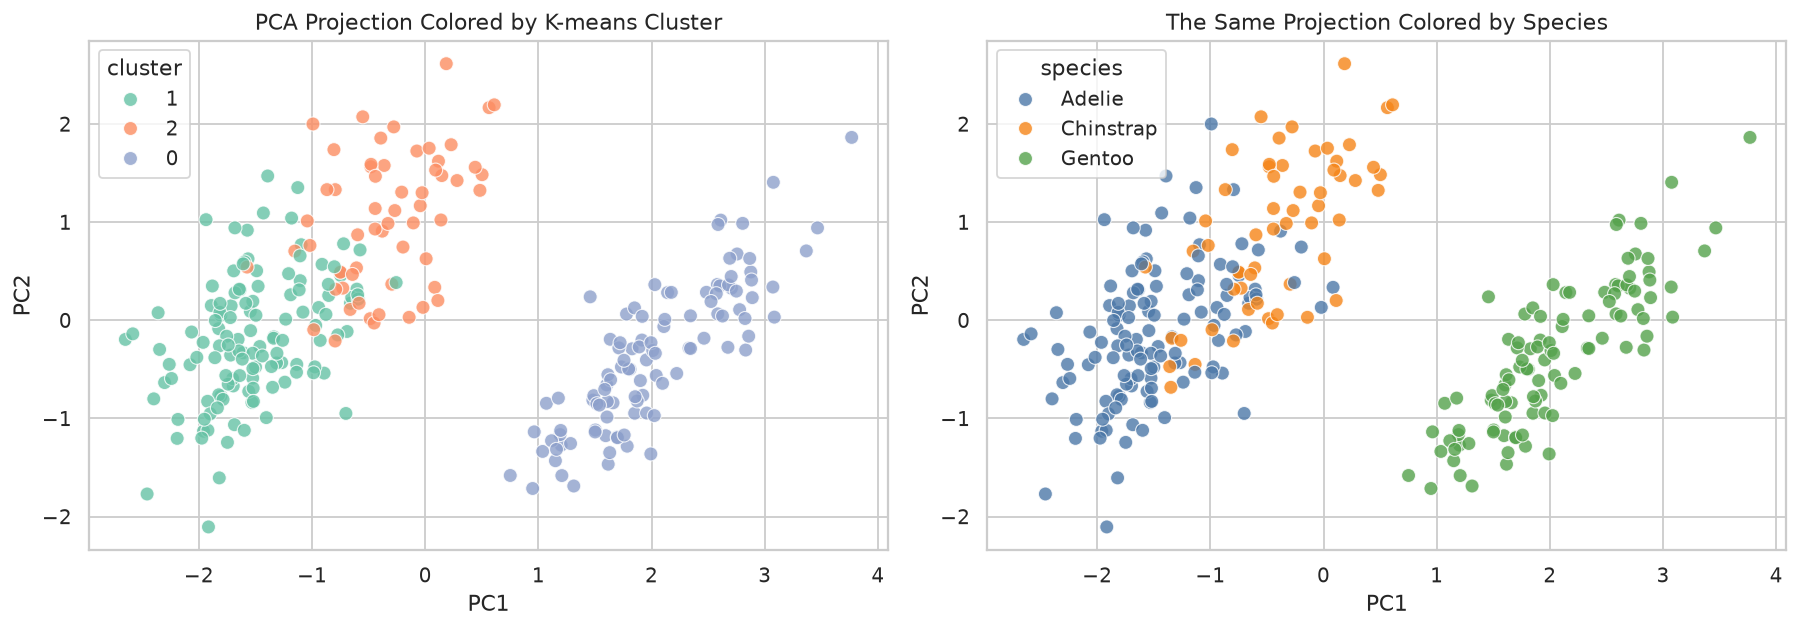

In [18]:
scaled_development = clustering_pipeline.named_steps["scaler"].transform(
    X_development
)
pca = PCA(n_components=2, random_state=SEED)
embedding = pca.fit_transform(scaled_development)

cluster_plot_df = pd.DataFrame(
    {
        "PC1": embedding[:, 0],
        "PC2": embedding[:, 1],
        "cluster": cluster_labels.astype(str),
        TARGET_COLUMN: y_development.reset_index(drop=True),
    }
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(
    data=cluster_plot_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    s=60,
    alpha=0.8,
    ax=axes[0],
)
axes[0].set_title("PCA Projection Colored by K-means Cluster")

sns.scatterplot(
    data=cluster_plot_df,
    x="PC1",
    y="PC2",
    hue=TARGET_COLUMN,
    hue_order=SPECIES_ORDER,
    palette=SPECIES_PALETTE,
    s=60,
    alpha=0.8,
    ax=axes[1],
)
axes[1].set_title("The Same Projection Colored by Species")

plt.tight_layout()
plt.show()

## 9. Conclusions and limitations

In [19]:
error_count = len(errors)
most_important_feature = importance_df.iloc[0]["feature"]

display(
    Markdown(
        f'''
### Final result

- **Selected model:** {best_model_name}
- **Five-fold CV macro F1:** {best_cv_macro_f1:.3f} ± {best_cv_macro_f1_std:.3f}
- **Validation macro F1:** {validation_macro_f1:.3f}
- **Test accuracy:** {test_accuracy:.3f}
- **Test macro F1:** {test_macro_f1:.3f}
- **Test errors:** {error_count} of {len(test_results)} observations
- **Largest permutation-importance estimate:** `{most_important_feature}`
- **K-means/species agreement:** ARI {ari:.3f}, NMI {nmi:.3f}

Physical measurements are sufficient to classify the three species with high accuracy in this dataset, without using island or sex as predictors. The selected model clearly outperforms the most-frequent baseline. K-means recovers part, but not all, of the labeled species structure: morphology contains natural grouping information, while supervised labels remain necessary to resolve overlapping groups reliably.
        '''
    )
)


### Final result

- **Selected model:** Logistic Regression
- **Five-fold CV macro F1:** 0.985 ± 0.012
- **Validation macro F1:** 0.977
- **Test accuracy:** 0.981
- **Test macro F1:** 0.975
- **Test errors:** 1 of 52 observations
- **Largest permutation-importance estimate:** `bill_length_mm`
- **K-means/species agreement:** ARI 0.900, NMI 0.866

Physical measurements are sufficient to classify the three species with high accuracy in this dataset, without using island or sex as predictors. The selected model clearly outperforms the most-frequent baseline. K-means recovers part, but not all, of the labeled species structure: morphology contains natural grouping information, while supervised labels remain necessary to resolve overlapping groups reliably.
        

### Limitations

- The dataset is small, so the estimates can vary with the particular split.
- The observations come from the Palmer Archipelago and may not generalize to other populations or measurement procedures.
- Two records with all four measurements missing were excluded.
- Subgroup results are descriptive because some test subgroups contain very few observations.
- Permutation importance measures predictive association, not causation.
- K-means assumes roughly spherical clusters and requires the number of clusters in advance; disagreement with species is therefore not evidence that the species labels are wrong.

## 10. Reproducibility

From the repository root:

```powershell
uv sync --frozen
uv run python -m penguins_project.train
uv run pytest -q
uv run jupyter lab
```

Open this notebook and choose **Kernel → Restart Kernel and Run All Cells**. Random operations use `SEED = 32`; exact dependency versions are recorded in `uv.lock`.

## 11. Artificial-intelligence use disclosure

ChatGPT was used as a learning and development assistant for explaining Pandera and Parquet, reviewing the deterministic split for leakage, debugging selected code fragments, suggesting a reproducible notebook structure, and helping draft or revise selected implementation and documentation sections. The methodological choices retained in the final project were checked against the course specification and verified by running the complete workflow, tests, metrics, and plots.

Representative prompts included:

- “Explain what each Penguins column represents and which Pandera checks are justified.”
- “Review this stratified train/validation/test split and identify possible leakage.”
- “Explain why macro F1 should accompany accuracy for these class frequencies.”
- “Show how to compare the candidate models with stratified cross-validation while keeping preprocessing inside a pipeline.”
- “Explain how K-means and PCA can be used as a separate unsupervised analysis without using species labels during fitting.”

